# 03 · Robustness Diagnostics, Interpretation and Findings

**PhilGEPS procurement-failure risk · Notebook 3 of 3 · Roadmap steps 7–9**
**Inputs:** the bid table from notebook 01, plus the split assignment and final model from notebook 02.

| Section | Question |
|---|---|
| 7.1 | What did the final model achieve on the random test set? |
| 7.2 | Does the model hold up on **later periods** it has not seen (train on 2023–2024, test on 2025 and 2026)? |
| 7.3 | Which inputs changed between periods and systems (drift)? |
| 7.4 | Where does the model work well, by classification and by quarter? |
| 7.5 | How much do incomplete labels limit the conclusions? |
| 8.1 | Which inputs does the model rely on? |
| 8.2–8.4 | How does the failure rate relate to budget size and procurement type? This is descriptive, not causal. |
| 8.5 | What would a review queue based on the score catch? |
| 9 | Findings, limitations, and answers to the reviewer's questions |

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.inspection import permutation_importance

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

bids = pd.read_parquet(pf.BIDS)
splits = pd.read_parquet(pf.SPLITS)
config = json.loads((pf.MODELS / "final_config.json").read_text())
final = joblib.load(pf.MODELS / "final_pipeline.joblib")
calibrated = joblib.load(pf.MODELS / "final_calibrated.joblib")
numeric, categorical = config["numeric"], config["categorical"]

for c in pf.KEY:
    bids[c] = bids[c].astype(str); splits[c] = splits[c].astype(str)
labelled = bids[bids.Target_Failed.notna()].merge(splits, on=pf.KEY, how="left")
assert labelled["split"].notna().all()
test = labelled[labelled.split == "test"].copy()
test["prob"] = calibrated.predict_proba(pf.model_frame(test, numeric, categorical))[:, 1]
print(f"Final model: {config['model']} ({config['feature_set']} features)")
print(f"Labelled bids: {len(labelled):,} | test: {len(test):,}")

Final model: Gradient boosting (expanded features)
Labelled bids: 573,585 | test: 86,038


## Phase 7. Robustness diagnostics

### 7.1 Recap: random-split test performance

In [2]:
recap = pd.DataFrame([{"Evaluation": "Random split, test set", **pf.summary_metrics(test.Target_Failed, test.prob)}])
display(recap)
display(pf.queue_metrics(test.Target_Failed, test.prob))

,Evaluation,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,"Random split, test set",86038,0.1207,0.8437,0.4956,0.5109,0.4233,4.2329


,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k
0,top 5%,4302,0.6520,0.2701,5.4019
1,top 10%,8604,0.5109,0.4233,4.2329
2,top 20%,17208,0.3816,0.6323,3.1612
3,top 30%,25811,0.3071,0.7632,2.5441
4,top 50%,43019,0.2183,0.9043,1.8086


### 7.2 Out-of-time check: train on 2023–2024, test on later periods

A random split lets the model learn from every period, including the one it is tested on. In practice, a score would be trained on past notices and applied to new ones. The final configuration is therefore refitted on bids **published in 2023–2024** (all PhilGEPS 1.5) and evaluated on:

- 2025 (PhilGEPS 1.5),
- 2026 PhilGEPS 1.5 notices,
- 2026 PhilGEPS 2.0 notices. The 2.0 vocabularies for category and funding source were never seen in 2023–2024.

The model is evaluated on raw scores (ranking metrics only). Calibration fitted on the random split would not transfer to a different period.

In [3]:
from sklearn.base import clone

past = labelled[labelled.published_year <= 2024]
oot_model = clone(final).fit(pf.model_frame(past, numeric, categorical), past.Target_Failed.astype(int))

periods = {
    "2025, PhilGEPS 1.5": labelled[(labelled.published_year == 2025) & (labelled["Source System"] == "1.5")],
    "2026, PhilGEPS 1.5": labelled[(labelled.published_year == 2026) & (labelled["Source System"] == "1.5")],
    "2026, PhilGEPS 2.0": labelled[(labelled.published_year == 2026) & (labelled["Source System"] == "2.0")],
}
rows = []
for name, frame in periods.items():
    score = oot_model.predict_proba(pf.model_frame(frame, numeric, categorical))[:, 1]
    rows.append({"Evaluation": f"Trained 2023–2024 → {name}", **pf.summary_metrics(frame.Target_Failed, score)})
    sub = test[(test.published_year == frame.published_year.iloc[0]) & (test["Source System"] == frame["Source System"].iloc[0])]
    rows.append({"Evaluation": f"Random split → same period ({name}), test bids only", **pf.summary_metrics(sub.Target_Failed, sub.prob)})
oot = pd.DataFrame(rows)
display(oot)
print(f"Training bids (2023–2024): {len(past):,}, failure rate {past.Target_Failed.mean() * 100:.2f}%")

,Evaluation,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,"Trained 2023–2024 → 2025, PhilGEPS 1.5",105365,0.1148,0.8263,0.4717,0.4756,0.4142,4.1422
1,"Random split → same period (2025, PhilGEPS 1.5...",15767,0.1144,0.8510,0.5195,0.5193,0.4540,4.5390
2,"Trained 2023–2024 → 2026, PhilGEPS 1.5",68666,0.1171,0.7452,0.3539,0.3674,0.3138,3.1375
3,"Random split → same period (2026, PhilGEPS 1.5...",10211,0.1180,0.8048,0.4391,0.4564,0.3867,3.8676
4,"Trained 2023–2024 → 2026, PhilGEPS 2.0",11983,0.3944,0.5609,0.4978,0.6185,0.1568,1.5683
5,"Random split → same period (2026, PhilGEPS 2.0...",1798,0.3943,0.8082,0.7520,0.9278,0.2355,2.3528


Training bids (2023–2024): 387,571, failure rate 11.45%


### 7.3 Drift: inputs never seen in training

A large share of unseen category values points to reporting or schema changes rather than a change in procurement behaviour. This is the main issue LT8 found for 2026 (LT8 §7.2), where 2026 came only from the 2.0 exports.

In [4]:
seen = {c: set(past[c].astype("string").fillna("Missing")) for c in categorical if c in past}
drift_rows = []
for name, frame in periods.items():
    row = {"Period": name, "Bids": len(frame)}
    for c in categorical:
        vals = frame[c].astype("string").fillna("Missing")
        row[c] = round((~vals.isin(seen[c])).mean() * 100, 1)
    drift_rows.append(row)
drift = pd.DataFrame(drift_rows).set_index("Period")
print("Share of bids (%) with a value not seen in 2023–2024 training data:")
display(drift)

Share of bids (%) with a value not seen in 2023–2024 training data:


,Bids,Funding Source,Business Category,Region,published_month,Classification,PE Organization Type (Grouped),Government Branch,Funding Instrument,Trade Agreement,Lot Type,published_dayofweek,Source System
Period,,,,,,,,,,,,,
"2025, PhilGEPS 1.5",105365,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"2026, PhilGEPS 1.5",68666,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"2026, PhilGEPS 2.0",11983,100.0000,99.7000,0.0000,0.0000,0.0000,0.1000,2.5000,100.0000,0.0000,100.0000,0.0000,100.0000


### 7.4 Performance by procurement classification and by quarter

Segment results on the random test set. Small segments (under 200 bids or a single class) are omitted. A high precision in a segment can simply reflect a high base failure rate, so read precision together with lift.

,Classification,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Civil Works,36722,0.0786,0.8391,0.4121,0.3657,0.4652,4.6521
1,Consulting Services,432,0.2917,0.8086,0.6093,0.6977,0.2381,2.3920
2,Goods,47284,0.1483,0.8342,0.5221,0.5709,0.3848,3.8483
3,Goods - General Support Services,1600,0.2238,0.7847,0.5332,0.6000,0.2682,2.6816


,source_quarter,Source System,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,2023Q1,1.5,6510,0.1131,0.8516,0.4955,0.4885,0.4321,4.3207
1,2023Q2,1.5,6983,0.1325,0.8417,0.5085,0.5430,0.4097,4.0991
2,2023Q3,1.5,6529,0.1222,0.8389,0.4924,0.5161,0.4223,4.2224
3,2023Q4,1.5,7776,0.1169,0.8357,0.4185,0.4653,0.3982,3.9804
4,2024Q1,1.5,6967,0.1019,0.8513,0.4999,0.4505,0.4423,4.4206
5,2024Q2,1.5,7304,0.1094,0.8456,0.4543,0.4658,0.4255,4.2577
6,2024Q3,1.5,7254,0.1137,0.8373,0.4258,0.4566,0.4012,4.0143
7,2024Q4,1.5,8939,0.1080,0.8426,0.4442,0.4485,0.4155,4.1550
8,2025Q1,1.5,7543,0.0846,0.8753,0.5094,0.4363,0.5157,5.1588
9,2025Q2,1.5,4113,0.1126,0.8336,0.4690,0.4793,0.4255,4.2580


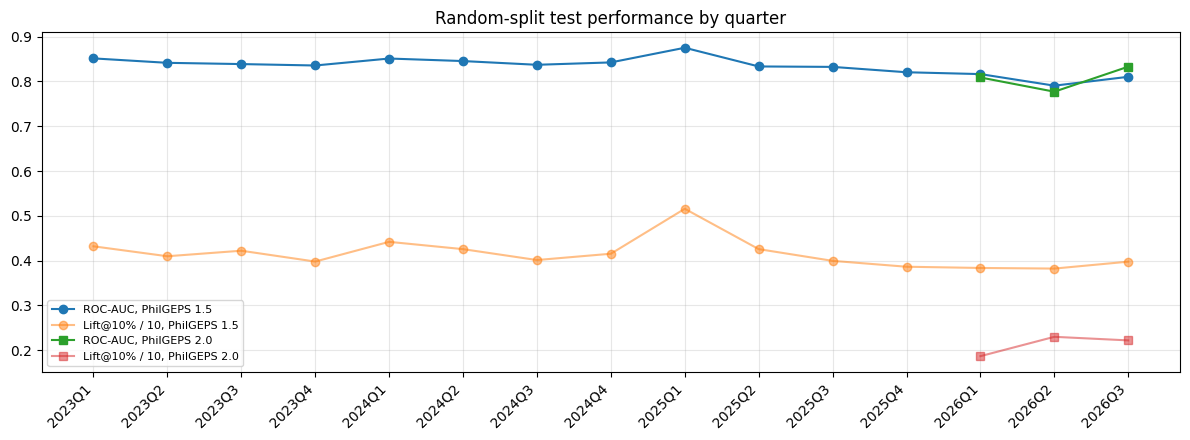

In [5]:
def by_group(frame, cols):
    rows = []
    for g, sub in frame.groupby(cols, observed=True):
        if sub.Target_Failed.nunique() == 2 and len(sub) >= 200:
            g = g if isinstance(g, tuple) else (g,)
            rows.append({**dict(zip(cols, g)), **pf.summary_metrics(sub.Target_Failed, sub.prob)})
    return pd.DataFrame(rows)

display(by_group(test, ["Classification"]))
by_q = by_group(test, ["source_quarter", "Source System"])
display(by_q)

fig, ax = plt.subplots(figsize=(12, 4.5))
for system, style in [("1.5", "-o"), ("2.0", "-s")]:
    s = by_q[by_q["Source System"] == system]
    ax.plot(s.source_quarter.astype(str), s["ROC-AUC"], style, label=f"ROC-AUC, PhilGEPS {system}")
    ax.plot(s.source_quarter.astype(str), s["Lift@10%"] / 10, style, alpha=.5, label=f"Lift@10% / 10, PhilGEPS {system}")
ax.set_title("Random-split test performance by quarter"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

### 7.5 Incomplete labels and outcome-selection bias

The model is trained and evaluated only on bids with a posted outcome. Two checks show how far that limits the conclusions:

1. **Label coverage by period.** This is the share of bids with a final Awarded/Failed status.
2. **Scores of unlabelled bids.** The model is applied to `Closed`, `Active` and `Cancelled` bids. If closed-without-outcome bids look like awarded bids to the model, the excluded population probably resembles the labelled one. If they look like failures, the labelled failure rate likely understates true failure.

bids  labelled      failed  Label coverage (%)  Failure rate among labelled (%)
published_year Source System                                                                                   
2023           1.5            344747    183946 22,109.0000             53.4000                          12.0200
2024           1.5            377940    203625 22,261.0000             53.9000                          10.9300
2025           1.5            320370    105365 12,098.0000             32.9000                          11.4800
2026           1.5            208153     68666  8,041.0000             33.0000                          11.7100
               2.0             26003     11983  4,726.0000             46.1000                          39.4400

bids   mean  median
status    Source System                       
Active    1.5             21213 0.1260  0.0660
          2.0              4079 0.4570  0.4670
Awarded   1.5             74564 0.0880  0.0460
          2.0              1089 0.2890  0.2420
Cancelled 1.5             60169 0.1300  0.0720
          2.0                13 0.4970  0.4820
Closed    1.5            607495 0.1650  0.0940
          2.0              9915 0.4880  0.4930
Failed    1.5              9676 0.3170  0.2420
          2.0               709 0.5730  0.5490

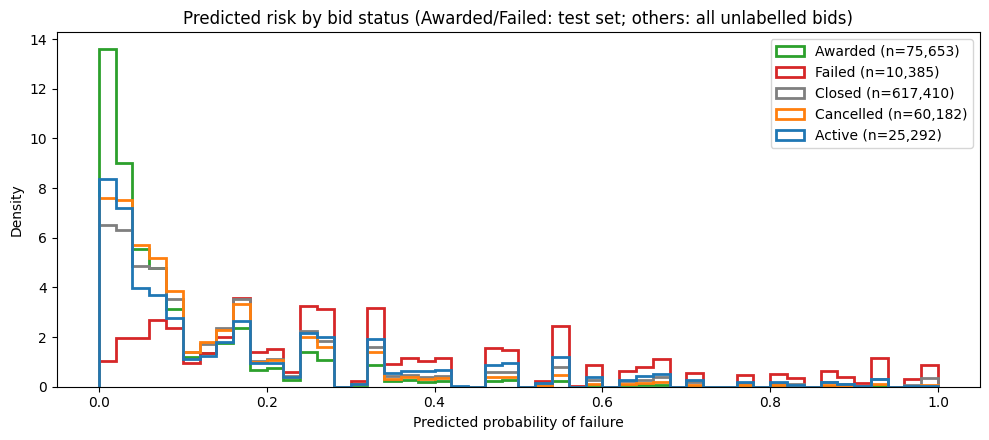

In [6]:
coverage = bids.groupby(["published_year", "Source System"], observed=True).agg(
    bids=("status", "size"), labelled=("Target_Failed", "count"), failed=("Target_Failed", "sum"))
coverage["Label coverage (%)"] = (coverage.labelled / coverage.bids * 100).round(1)
coverage["Failure rate among labelled (%)"] = (coverage.failed / coverage.labelled * 100).round(2)
display(coverage)

unlabelled = bids[bids.Target_Failed.isna() & bids.status.isin(["Closed", "Active", "Cancelled"])]
unlabelled_prob = calibrated.predict_proba(pf.model_frame(unlabelled, numeric, categorical))[:, 1]
scores = pd.concat([
    pd.DataFrame({"status": test.status, "Source System": test["Source System"], "predicted risk": test.prob}),
    pd.DataFrame({"status": unlabelled.status.values, "Source System": unlabelled["Source System"].values, "predicted risk": unlabelled_prob}),
])
display(scores.groupby(["status", "Source System"], observed=True)["predicted risk"]
        .agg(bids="size", mean="mean", median="median").round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
for status, color in [("Awarded", "tab:green"), ("Failed", "tab:red"), ("Closed", "tab:gray"), ("Cancelled", "tab:orange"), ("Active", "tab:blue")]:
    s = scores.loc[scores.status == status, "predicted risk"]
    ax.hist(s, bins=50, range=(0, 1), density=True, histtype="step", lw=2, label=f"{status} (n={len(s):,})", color=color)
ax.set_xlabel("Predicted probability of failure"); ax.set_ylabel("Density")
ax.set_title("Predicted risk by bid status (Awarded/Failed: test set; others: all unlabelled bids)")
ax.legend(); plt.tight_layout(); plt.show()

## Phase 8. Interpretation

### 8.1 Permutation importance

Each input is shuffled in turn on a 60,000-bid stratified sample of the test set. The resulting drop in PR-AUC is recorded and averaged over three repeats. Importance measures how much the model depends on an input. It is **not** a causal effect, and correlated inputs share credit.

,Feature,Mean drop in PR-AUC,Std
0,Region,0.2006,0.0024
1,log_approved_budget,0.1811,0.0028
2,Business Category,0.1472,0.0034
3,Funding Instrument,0.0886,0.0018
4,log_contract_duration_days,0.0681,0.0038
5,PE Organization Type (Grouped),0.0546,0.0011
6,bidding_window_days,0.0518,0.0014
7,log_n_line_items,0.0501,0.0015
8,published_month,0.0202,0.0011
9,Classification,0.0079,0.0007


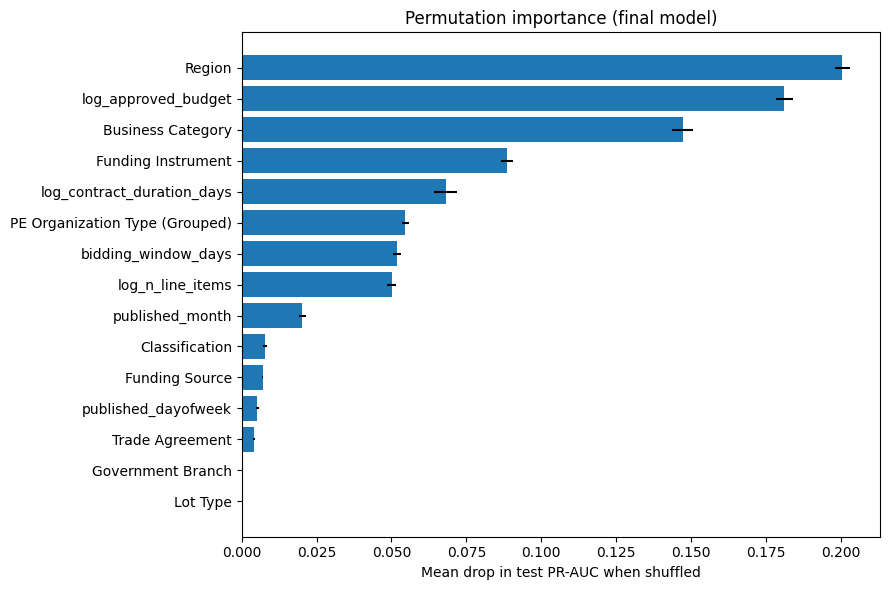

In [7]:
from sklearn.model_selection import train_test_split
sample, _ = train_test_split(test, train_size=min(60_000, len(test) - 1), stratify=test.Target_Failed,
                             random_state=pf.RANDOM_STATE)
X_s = pf.model_frame(sample, numeric, categorical)
imp = permutation_importance(final, X_s, sample.Target_Failed.astype(int), scoring="average_precision",
                             n_repeats=3, random_state=pf.RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"Feature": X_s.columns, "Mean drop in PR-AUC": imp.importances_mean,
                            "Std": imp.importances_std})
              .sort_values("Mean drop in PR-AUC", ascending=False).reset_index(drop=True))
display(importance)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.Feature, top["Mean drop in PR-AUC"], xerr=top.Std, color="tab:blue")
plt.xlabel("Mean drop in test PR-AUC when shuffled"); plt.title("Permutation importance (final model)")
plt.tight_layout(); plt.show()

### 8.2 Observed failure rate by budget decile

Labelled PhilGEPS 1.5 bids are grouped into ten equal-sized bands of approved budget. 2.0 bids are left out so the comparison is not mixed with the 2.0 reporting differences. This is descriptive: it shows where failures concentrate, not that budget size causes failure.

,bids,failure_rate,min,max
budget_decile,,,,
1,56163,0.2630,1.0000,"197,925.0000"
2,56523,0.1505,"197,932.0000","360,000.0000"
3,55798,0.1128,"360,000.4600","613,350.0000"
4,59087,0.0939,"613,369.0500","1,000,000.0000"
5,53276,0.1140,"1,000,000.0100","1,600,000.0000"
6,59333,0.0986,"1,600,010.0000","2,500,000.0000"
7,52946,0.0910,"2,500,014.9600","4,375,000.0000"
8,56155,0.0740,"4,375,006.0000","7,381,550.9400"
9,56666,0.0733,"7,381,732.5000","19,800,000.0000"


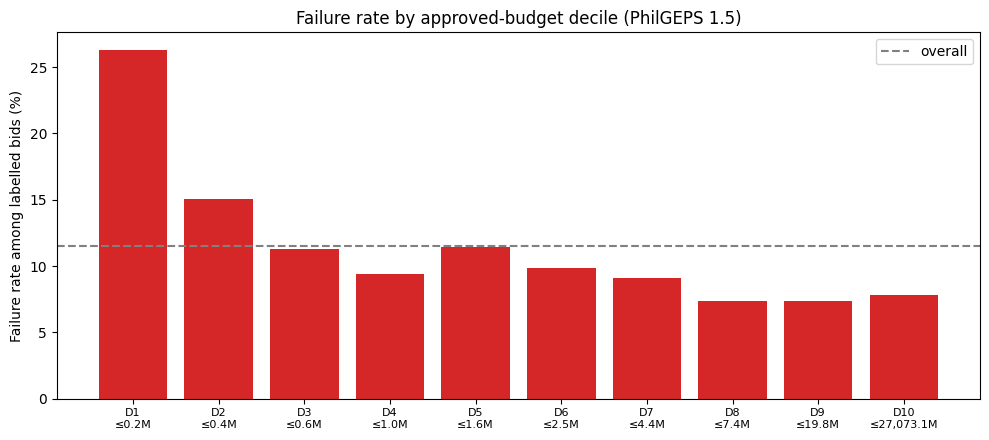

In [8]:
l15 = labelled[labelled["Source System"] == "1.5"].copy()
l15["budget_decile"] = pd.qcut(l15.approved_budget, 10, labels=False) + 1
edges = l15.groupby("budget_decile").approved_budget.agg(["min", "max"])
dec = l15.groupby("budget_decile").Target_Failed.agg(bids="size", failure_rate="mean").join(edges)
display(dec)

plt.figure(figsize=(10, 4.5))
plt.bar(dec.index, dec.failure_rate * 100, color="tab:red")
plt.axhline(l15.Target_Failed.mean() * 100, ls="--", color="gray", label="overall")
plt.xticks(dec.index, [f"D{i}\n≤{m / 1e6:,.1f}M" for i, m in zip(dec.index, dec["max"])], fontsize=8)
plt.ylabel("Failure rate among labelled bids (%)"); plt.title("Failure rate by approved-budget decile (PhilGEPS 1.5)")
plt.legend(); plt.tight_layout(); plt.show()

### 8.3 Budget pattern by classification

Goods and Civil Works have very different budget distributions, so the overall budget pattern can mix two different relationships. The deciles here are the common ones from §8.2.

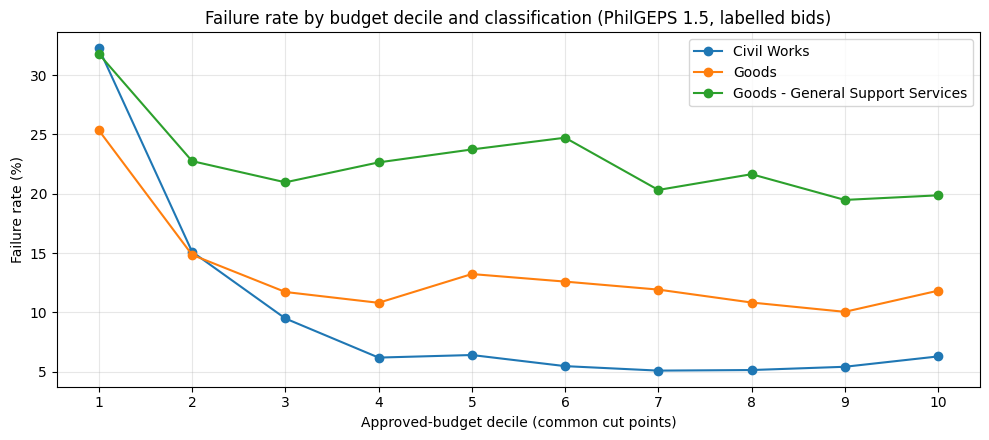

Classification,Civil Works,Goods,Goods - General Support Services
budget_decile,,,
1,0.3225,0.2535,0.3179
2,0.1511,0.1486,0.2276
3,0.0950,0.1173,0.2097
4,0.0620,0.1082,0.2265
5,0.0642,0.1324,0.2374
6,0.0548,0.1260,0.2473
7,0.0510,0.1193,0.2033
8,0.0515,0.1084,0.2165
9,0.0543,0.1006,0.1949


In [9]:
strat = (l15[l15.Classification.isin(["Goods", "Civil Works", "Goods - General Support Services"])]
         .groupby(["Classification", "budget_decile"]).Target_Failed.agg(bids="size", failure_rate="mean").reset_index())
plt.figure(figsize=(10, 4.5))
for cls, sub in strat.groupby("Classification"):
    sub = sub[sub.bids >= 200]
    plt.plot(sub.budget_decile, sub.failure_rate * 100, "o-", label=cls)
plt.xlabel("Approved-budget decile (common cut points)"); plt.ylabel("Failure rate (%)")
plt.title("Failure rate by budget decile and classification (PhilGEPS 1.5, labelled bids)")
plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(strat.pivot(index="budget_decile", columns="Classification", values="failure_rate").round(4))

### 8.4 Adjusted failure curves

A logistic regression of `Target_Failed` on budget decile × classification, adjusted for region and source quarter. It is fitted on labelled PhilGEPS 1.5 Goods and Civil Works bids. The adjusted curves average the model's predictions over each classification's own mix of regions and quarters. This is an association analysis on labelled bids, not a causal estimate.

Observations: 548,405 | pseudo R-squared: 0.0680 | converged: True


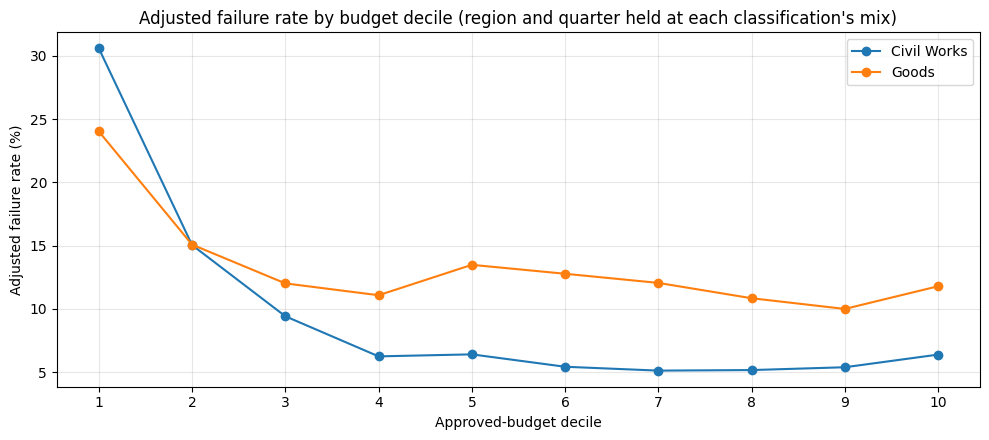

Classification,Civil Works,Goods
budget_decile,,
1,0.3058,0.2402
2,0.1504,0.1508
3,0.0942,0.1202
4,0.0626,0.1108
5,0.0641,0.1349
6,0.0543,0.1278
7,0.0513,0.1206
8,0.0517,0.1085
9,0.0540,0.1000


In [10]:
glm_df = l15[l15.Classification.isin(["Goods", "Civil Works"])][
    ["Target_Failed", "budget_decile", "Classification", "Region", "source_quarter"]].copy()
for c in ["Classification", "Region", "source_quarter"]:
    glm_df[c] = glm_df[c].astype(str)
glm_df["budget_decile"] = glm_df["budget_decile"].astype(int)
glm = smf.logit("Target_Failed ~ C(budget_decile) * C(Classification) + C(Region) + C(source_quarter)",
                data=glm_df).fit(disp=False, maxiter=200)
print(f"Observations: {int(glm.nobs):,} | pseudo R-squared: {glm.prsquared:.4f} | converged: {glm.mle_retvals['converged']}")

curves = []
for cls in ["Goods", "Civil Works"]:
    base = glm_df[glm_df.Classification == cls]
    for d in range(1, 11):
        curves.append({"Classification": cls, "budget_decile": d,
                       "adjusted failure rate": glm.predict(base.assign(budget_decile=d)).mean()})
curves = pd.DataFrame(curves)
plt.figure(figsize=(10, 4.5))
for cls, sub in curves.groupby("Classification"):
    plt.plot(sub.budget_decile, sub["adjusted failure rate"] * 100, "o-", label=cls)
plt.xlabel("Approved-budget decile"); plt.ylabel("Adjusted failure rate (%)")
plt.title("Adjusted failure rate by budget decile (region and quarter held at each classification's mix)")
plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(curves.pivot(index="budget_decile", columns="Classification", values="adjusted failure rate").round(4))

### 8.5 Review-queue simulation

This puts the test-set results in operational terms. Suppose a review team can look at a fixed share of newly published notices. How many failed procurements would be in their queue, compared with picking notices at random? This is a historical simulation on labelled test bids. It does not show that reviewing a notice prevents failure.

In [11]:
queue = pf.queue_metrics(test.Target_Failed, test.prob)
queue["Failures caught"] = (queue["Precision@k"] * queue["Notices reviewed"]).round().astype(int)
queue["Failures caught at random"] = (test.Target_Failed.mean() * queue["Notices reviewed"]).round().astype(int)
display(queue)

risk_bands = pd.qcut(test.prob.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
band = test.groupby(risk_bands, observed=True).agg(bids=("prob", "size"), mean_predicted=("prob", "mean"),
                                                   observed_failure_rate=("Target_Failed", "mean"))
display(band)

,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k,Failures caught,Failures caught at random
0,top 5%,4302,0.6520,0.2701,5.4019,2805,519
1,top 10%,8604,0.5109,0.4233,4.2329,4396,1039
2,top 20%,17208,0.3816,0.6323,3.1612,6566,2077
3,top 30%,25811,0.3071,0.7632,2.5441,7926,3115
4,top 50%,43019,0.2183,0.9043,1.8086,9391,5192


,bids,mean_predicted,observed_failure_rate
prob,,,
D1,8604,0.0031,0.0044
D2,8604,0.0142,0.0139
D3,8604,0.0211,0.0201
D4,8603,0.0296,0.0317
D5,8604,0.0467,0.0453
D6,8604,0.0679,0.0711
D7,8603,0.1004,0.0986
D8,8604,0.1588,0.1585
D9,8604,0.2459,0.2520


## Phase 9. Findings and limitations

The key figures are collected below from the saved outputs of notebooks 01–03. The narrative follows the table.

In [12]:
val_results = pd.read_csv(pf.MODELS / "validation_results.csv")
sens = pd.read_csv(pf.MODELS / "sensitivity_cancelled.csv")
lab = labelled
key_figures = pd.DataFrame([
    ("Public Bidding bids (after quality exclusions)", f"{len(bids):,}"),
    ("Labelled bids (Awarded or Failed)", f"{len(lab):,}"),
    ("Awarded / Failed", f"{int((lab.Target_Failed == 0).sum()):,} / {int(lab.Target_Failed.sum()):,}"),
    ("Failure rate among labelled bids", f"{lab.Target_Failed.mean() * 100:.2f}%"),
    ("Failure rate, PhilGEPS 1.5 / 2.0", " / ".join(f"{lab[lab['Source System'] == s].Target_Failed.mean() * 100:.1f}%" for s in ["1.5", "2.0"])),
    ("Final model", f"{config['model']} ({config['feature_set']} features)"),
    ("Best validation PR-AUC, original 5 features", f"{val_results[val_results['Feature set'] == 'original_5']['PR-AUC'].max():.3f}"),
    ("Best validation PR-AUC, expanded features", f"{val_results[val_results['Feature set'] == 'expanded']['PR-AUC'].max():.3f}"),
    ("Test ROC-AUC / PR-AUC", f"{config['test']['ROC-AUC']:.3f} / {config['test']['PR-AUC']:.3f}"),
    ("Test top-10% precision / recall / lift", f"{config['test']['Precision@10%'] * 100:.1f}% / {config['test']['Recall@10%'] * 100:.1f}% / {config['test']['Lift@10%']:.2f}x"),
] + [(f"Out-of-time ROC-AUC: {r.Evaluation.replace('Trained 2023–2024 → ', 'trained 2023–2024, tested ')}", f"{r['ROC-AUC']:.3f} (lift@10% {r['Lift@10%']:.2f}x)")
     for _, r in oot[oot.Evaluation.str.startswith("Trained")].iterrows()]
  + [("Sensitivity (Failed or Cancelled) test ROC-AUC / PR-AUC", f"{sens.iloc[1]['ROC-AUC']:.3f} / {sens.iloc[1]['PR-AUC']:.3f}")],
    columns=["Quantity", "Value"])
display(key_figures)

,Quantity,Value
0,Public Bidding bids (after quality exclusions),"1,277,213"
1,Labelled bids (Awarded or Failed),"573,585"
2,Awarded / Failed,"504,350 / 69,235"
3,Failure rate among labelled bids,12.07%
4,"Failure rate, PhilGEPS 1.5 / 2.0",11.5% / 39.4%
5,Final model,Gradient boosting (expanded features)
6,"Best validation PR-AUC, original 5 features",0.395
7,"Best validation PR-AUC, expanded features",0.510
8,Test ROC-AUC / PR-AUC,0.844 / 0.496
9,Test top-10% precision / recall / lift,51.1% / 42.3% / 4.23x


### Findings

1. **Failure risk can be ranked from publication-time information.** On a held-out random 15% of the merged 1.5 + 2.0 bids, gradient boosting reaches **ROC-AUC 0.844 and PR-AUC 0.496**, against 0.121 for a random ranking. Reviewing the **10% of notices with the highest predicted risk** finds failures in 51% of them and catches **42% of all failed biddings**, 4.2 times the random rate (§7.1, §8.5). After calibration, the scores can be read as probabilities. In the top risk decile, the mean predicted risk is 51.5% and 51.1% of those bids actually failed.
2. **More at-publication information helps substantially.** With LT8's five features, the best validation PR-AUC is 0.395. The expanded set adds bidding window, line items, contract duration, organisation type, funding instrument and source system, and raises it to 0.510 (notebook 02, §6.6). Gradient boosting is the best of the four models with either feature set.
3. **What drives the score.** The model relies most on region, approved budget and procurement category, followed by funding instrument, contract duration, organisation type, bidding window and number of line items (§8.1). These are associations, not causes.
4. **Small procurements fail most often.** Among PhilGEPS 1.5 bids, the failure rate is 26% in the lowest budget decile (up to about ₱198,000), against 7–8% in the top three deciles. The pattern holds after adjusting for region and quarter. It is much steeper for Civil Works (31% → 5–6%) than for Goods, which stays around 10–13% from the third decile up (§8.2–8.4).
5. **Performance holds over time within PhilGEPS 1.5, with some decay.** A model trained only on 2023–2024 still ranks 2025 notices well (ROC-AUC 0.826, lift 4.1×). On 2026 PhilGEPS 1.5 notices it reaches ROC-AUC 0.745 (lift 3.1×). The random split overstates real forward performance somewhat (0.80–0.85 on the same periods), so a deployed model should be retrained regularly.
6. **PhilGEPS 2.0 is a different reporting world.** Its notices use different category and funding vocabularies: 100% of 2.0 funding-source values and 99.7% of 2.0 categories were never seen in 2023–2024 data (§7.3). A model trained only on the past reaches ROC-AUC 0.561 on them, barely better than chance. Trained on the merged data, it ranks 2.0 notices well (ROC-AUC 0.808 on the test set). 2.0 notices also fail far more often among labelled bids (39% vs 11.5%), which may reflect the new platform's labelling as much as real failure. The 2.0 sample is small (11,983 labelled bids) and covers one year.
7. **The definition of failure matters little for ranking.** Counting cancellations as failures gives a model with test ROC-AUC 0.788 on that broader outcome. The same model still ranks failed vs awarded bids nearly as well as the main model (ROC-AUC 0.822 vs 0.844) (notebook 02, §6.10).

### Limitations

1. **Incomplete, non-random labels.** Only 45% of Public Bidding bids have a posted outcome, and coverage falls to about a third in 2025–2026. All metrics describe bids with a posted outcome. Unlabelled `Closed` bids receive higher average predicted risk than awarded bids (§7.5), so the true failure rate among all notices may be higher than the labelled rate suggests.
2. **Random split.** As agreed, the main evaluation uses a random split of the merged data, so the model learns from every period it is tested on. §7.2 shows how much that flatters forward performance; quote both numbers.
3. **Final-state snapshots.** All predictors are fields of the published notice, but the extracts show each notice's final state. An edit made after publication cannot be detected.
4. **Source differences.** `Business Category`, `Funding Source` and `Award Notice Status` use different vocabularies in PhilGEPS 2.0, and the 2.0 sample is small. Results for 2.0 are less certain than for 1.5.
5. **Observational evaluation.** The review-queue figures are a historical simulation. They do not show that reviewing a notice prevents failure.
6. **Scope.** Only Public Bidding is modelled. Other procurement modes and 259 bids with inconsistent key fields are excluded.

### Answers to the reviewer's questions

| # | Question | Answer |
|---|---|---|
| 1 | How does predicting awarded vs failed help suppliers decide which bids to pursue? | It is not designed to. The project is positioned as **predicting the likelihood of procurement failure** for a notice. It helps agencies and oversight bodies decide which notices to review early. For suppliers it is at most a signal that a notice is likely to fail, which says nothing about their own chance of winning. |
| 2 | Are all features available at publication? | Yes. Every predictor is part of the notice when it is posted; notebook 01 §5.6 classifies every field. Award and contract fields are excluded. Caveat: final-state snapshots (limitation 3). |
| 3 | How are ongoing, cancelled and closed bids handled? | They are not treated as failures. Only bids whose line items are all `Awarded` (0) or all `Failed` (1) are labelled; `Active`, `Closed`, `Cancelled`, `Shortlisted` and conflicting bids are excluded. Counting cancellations as failures is tested separately (finding 7). |
| 4 | How many observations, and what is the class distribution? | 1,277,213 Public Bidding bids. 573,585 are labelled: 504,350 Awarded and 69,235 Failed (12.1% failed). Training, validation and test sets have 401,509, 86,038 and 86,038 bids, each stratified to the same failure rate. |

### Recommended next steps

1. Retrain periodically, and track forward performance on newly resolved notices rather than relying on the random split alone.
2. Map the PhilGEPS 2.0 category and funding vocabularies to the 1.5 ones (or to UNSPSC segments) as more 2.0 data accumulates.
3. Before any operational use, run a prospective pilot. Score notices at publication, record the eventual outcomes, and measure the review workload and false positives.